# Learn image compression with ScaleHyperprior

**Audience:** a beginner who knows basic Python but is new to PyTorch and learned image compression.

**Our question:** can a neural network represent an image using fewer bits while keeping it recognizable?
We will use a model that already knows how to compress images, then try a very small training experiment.

## How to use this notebook

1. Select **Python (dip-project1)** as the kernel.
2. Run cells **from top to bottom**, using **Shift+Enter**. A cell normally uses variables created above it.
3. Read the explanation, run the next cell, then inspect its printed values or picture.
4. If you change an earlier setting, **restart the kernel and Run All** to avoid mixing old and new variables.

**First pass:** study Parts 1-7: setup, an image, a pretrained model, compression, and image-quality measurements.
**Second pass:** Parts 8-10 teach training and evaluation on other images.
**Optional appendix:** saved bitstreams, model sizes, checks, and experiment records. These also run with Run All,
but you do not need to understand their implementation on your first reading.

The default experiment is deliberately small: **2 DIV2K training images, 1 DIV2K validation image,
1 Kodak image, 1 Tecnick image, and 3 training steps**. It is not a completed training run or a full benchmark.
Previously downloaded images are reused. No multi-GB download starts unless you explicitly enable it.

The [project setup instructions](../README.md#scalehyperprior-notebook) describe dependency installation.
This lesson uses [CompressAI](https://interdigitalinc.github.io/CompressAI/) and the
[scale-hyperprior paper](https://arxiv.org/abs/1802.01436).

## A small vocabulary

| Word | Plain-language meaning |
|---|---|
| Pixel | One location in an image; an RGB pixel has red, green, and blue values. |
| Tensor | PyTorch's name for a multidimensional array of numbers. |
| Model / weights | A calculation with learned numbers that control its behavior. |
| Encoder / decoder | The parts that turn an image into a representation and turn it back into an image. |
| Bitstream | The actual sequence of encoded bytes we can save or transmit. |
| Rate / distortion | How many bits we use / how much the reconstructed image differs from the original. |

## 1. Prepare the environment

### 1.1 Help Windows find Conda's libraries

`os`, `sys`, and `Path` are standard Python tools for the operating system, interpreter, and file paths.
The Windows-only lines let PyTorch find libraries inside the selected Conda environment.
**This is environment setup, not part of the compression algorithm.** Keep the returned handle alive.

In [1]:
import os
import sys
from pathlib import Path

_conda_dll_handles = []
_conda_bin = Path(sys.prefix) / 'Library' / 'bin'
if sys.platform == 'win32' and _conda_bin.is_dir():
    os.environ['PATH'] = str(_conda_bin) + os.pathsep + os.environ.get('PATH', '')
    _conda_dll_handles.append(os.add_dll_directory(str(_conda_bin)))

### 1.2 Keep downloads secure

The small dataset downloads use HTTPS. `truststore` lets Python use the operating system's trusted certificates,
including those used on a university or company network. Certificate checking is **not** disabled.

In [2]:
import truststore

truststore.inject_into_ssl()

### 1.3 Import the tools for images and models

`numpy` stores arrays, `PIL.Image` opens images, and `matplotlib` draws pictures.
`torch` runs the neural network; `torchvision` converts images into tensors.
`pandas` displays small results tables. Importing a library does not train a model.

In [3]:
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torchvision
import compressai
from PIL import Image
from IPython.display import display
from torchvision import transforms
from torchvision.transforms.functional import to_tensor, to_pil_image

C:\ProgramData\miniconda3\envs\dip-project1\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1.4 Import a few file and download tools

`RemoteZip` can read one image inside an online ZIP without downloading the whole ZIP.
`requests` downloads an individual file. `BytesIO` lets an image reader inspect downloaded bytes.
The remaining tools are used later to save results and measure elapsed time.

In [4]:
import copy
import hashlib
import json
import struct
from datetime import datetime, timezone
from io import BytesIO
from time import perf_counter
import requests
from remotezip import RemoteZip
from compressai.models import ScaleHyperprior
from compressai.zoo import bmshj2018_hyperprior
from compressai.zoo.image import cfgs
from pytorch_msssim import ms_ssim

### 1.5 Check that the intended environment is running

Look for **dip-project1** in the interpreter path and **CompressAI 1.2.8** below.
ANS is the entropy coder: it packs the model's quantized numbers into bytes.
An `assert` is a check that stops execution if a requirement is not met.

In [5]:
print('Interpreter:', sys.executable)
print('PyTorch:', torch.__version__)
print('CompressAI:', compressai.__version__)
print('Available entropy coders:', compressai.available_entropy_coders())
assert compressai.__version__ == '1.2.8', 'Update the environment using environment.yml.'
assert 'ans' in compressai.available_entropy_coders()
compressai.set_entropy_coder('ans')

Interpreter: C:\ProgramData\miniconda3\envs\dip-project1\python.exe
PyTorch: 2.13.0
CompressAI: 1.2.8
Available entropy coders: ['ans']


### 1.6 Start with one quality setting

`QUALITY=3` selects one set of pretrained weights. Later we compare qualities 1, 3, and 5.
A random seed makes this notebook's random choices repeatable on the same setup.
We use the **CPU for all encoding and decoding** so the two operations use the same environment.
A GPU is used only in the training section, if available.

Keep these defaults on your first run. Seeds do not guarantee identical results across different hardware.

In [6]:
QUALITY = 3
CROP_SIZE = 256
SEED = 42
CODEC_DEVICE = torch.device('cpu')

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

### 1.7 Find the project directory

`Path.cwd()` means "the current working directory". We search it and its parents for this project.
If this check fails, launch Jupyter from the repository or its models directory.
The `/` operator between `Path` objects joins folder names; it creates the correct Windows path.

In [7]:
REPO_ROOT = None
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / 'environment.yml').is_file() and (folder / 'models').is_dir():
        REPO_ROOT = folder
        break
if REPO_ROOT is None:
    raise FileNotFoundError('Launch Jupyter from the repository or its models directory.')
print('Project:', REPO_ROOT)

Project: c:\Users\abdelazm\OneDrive - STMicroelectronics\Myspace\master\Digital_Image\git\Digial_Image_Processing_Project_CSE681


### 1.8 Decide where data and results live

Original images go into `data`; generated files go into `models/outputs/scale_hyperprior`.
These folders are ignored by Git. Re-running this notebook updates its output files.
To keep a separate experiment, change `OUTPUT_DIR` before running it.
If you already have datasets elsewhere, edit `DATA_DIRS` or set the `DIP_DATA_ROOT` environment variable.

In [8]:
DATA_ROOT = Path(os.environ.get('DIP_DATA_ROOT', str(REPO_ROOT / 'data'))).expanduser().resolve()
DATA_DIRS = {
    'DIV2K train': DATA_ROOT / 'DIV2K' / 'DIV2K_train_HR',
    'DIV2K validation': DATA_ROOT / 'DIV2K' / 'DIV2K_valid_HR',
    'Kodak': DATA_ROOT / 'Kodak',
    'Tecnick': DATA_ROOT / 'Tecnick' / 'RGB_OR_1200x1200',
}
OUTPUT_DIR = REPO_ROOT / 'models' / 'outputs' / 'scale_hyperprior'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Data:', DATA_ROOT)
print('Results:', OUTPUT_DIR)

Data: C:\Users\abdelazm\OneDrive - STMicroelectronics\Myspace\master\Digital_Image\git\Digial_Image_Processing_Project_CSE681\data
Results: c:\Users\abdelazm\OneDrive - STMicroelectronics\Myspace\master\Digital_Image\git\Digial_Image_Processing_Project_CSE681\models\outputs\scale_hyperprior


## 2. Get a few real dataset images

### 2.1 Why do we need different image groups?

| Group | What we use it for | Complete dataset |
|---|---|---|
| DIV2K train | Change the model's weights during training. | 800 original high-resolution images |
| DIV2K validation | Check progress without training on these images. | 100 high-resolution images |
| Kodak | Test on a separate collection, never use it for training. | 24 RGB images |
| Tecnick | Test on another separate collection. | 100 RGB 1200 x 1200 images |

We first download **two training images and one image from each other group**.
This keeps the lesson small while using the real original images.

Sources and usage terms:
- [DIV2K](https://data.vision.ee.ethz.ch/cvl/DIV2K/): academic research use; original owners retain image copyright.
  Full train + validation downloads are roughly 4 GB; the commonly quoted 3.5 GB is approximate.
- [Kodak](https://r0k.us/graphics/kodak/): consult the provider's usage and attribution notice.
- [Tecnick / TESTIMAGES](https://testimages.org/): Nicola Asuni / Tecnick.com,
  [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/).
  We use the historical RGB 1200 x 1200 set, not artificial/grayscale images or the newer 40-image 2400 px set.

### 2.2 Describe the expected filenames

Python's `range(1, 801)` gives 1 through 800; the final number is excluded.
`:04d` means "write an integer using four digits", so 1 becomes `0001`.
These lists let us distinguish a small example from a complete dataset.

In [9]:
DIV2K_TRAIN_URL = 'https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip'
DIV2K_VALID_URL = 'https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip'
KODAK_BASE_URL = 'https://r0k.us/graphics/kodak/kodak/'
TECNICK_URL = 'https://downloads.sourceforge.net/project/testimages/OLD/OLD_SAMPLING/testimages.zip'
EXPECTED_NAMES = {
    'DIV2K train': [f'{i:04d}.png' for i in range(1, 801)],
    'DIV2K validation': [f'{i:04d}.png' for i in range(801, 901)],
    'Kodak': [f'kodim{i:02d}.png' for i in range(1, 25)],
    'Tecnick': [f'RGB_OR_1200x1200_{i:03d}.png' for i in range(1, 101)],
}

### 2.3 Select a small download

**Leave `DOWNLOAD_FULL_DATASETS=False` for this lesson.** Changing it to True requests several GB.
`names[:count]` selects only the first few filenames.
Set `DOWNLOAD_DATA=False` if files must already exist; missing files will produce an explicit error.

In [10]:
DOWNLOAD_DATA = True
DOWNLOAD_FULL_DATASETS = False
DEMO_COUNTS = {'DIV2K train': 2, 'DIV2K validation': 1, 'Kodak': 1, 'Tecnick': 1}
REQUESTED_NAMES = {}
for label, names in EXPECTED_NAMES.items():
    if DOWNLOAD_FULL_DATASETS:
        REQUESTED_NAMES[label] = names
    else:
        REQUESTED_NAMES[label] = names[:DEMO_COUNTS[label]]

### 2.4 Check downloaded images before using them

A function groups instructions that we will reuse. `def` defines it; the instructions run when we call it.
`with Image.open(...)` automatically closes the file afterward.
The first function checks an existing RGB PNG. The second checks downloaded bytes and then saves them.
A temporary `.part` file is renamed only after it has been written.

These are download-safety helpers, not neural-network operations. You can run them as supplied.

In [11]:
def verify_rgb_png(path):
    with Image.open(path) as image:
        if image.format != 'PNG' or image.mode != 'RGB':
            raise ValueError(f'Expected an original RGB PNG: {path}')
        image.verify()

def save_verified_png(raw, target):
    with Image.open(BytesIO(raw)) as image:
        if image.format != 'PNG' or image.mode != 'RGB':
            raise ValueError(f'Download is not an RGB PNG: {target}')
        image.verify()
    target.parent.mkdir(parents=True, exist_ok=True)
    temporary = target.with_suffix('.png.part')
    temporary.write_bytes(raw)
    temporary.replace(target)

### 2.5 Read only the chosen images from a ZIP

Think of a ZIP as a folder stored on a server. `RemoteZip` asks for the bytes of the particular image we need,
using HTTP Range requests. It does **not** need the whole archive for a small selection.
Existing files are reused and verified. If the server cannot provide ranges, an error is shown instead of
silently downloading the entire archive.

Read this function from top to bottom: find missing names, download them, then verify the requested files.

In [12]:
def download_zip_pngs(url, prefix, names, folder):
    missing = [name for name in names if not (folder / name).is_file()]
    if missing and not DOWNLOAD_DATA:
        raise FileNotFoundError(f'Missing {len(missing)} images in {folder}. Enable DOWNLOAD_DATA or supply them.')
    if missing:
        with RemoteZip(url, timeout=120) as archive:
            for name in missing:
                print('Downloading ZIP member:', prefix + name, flush=True)
                save_verified_png(archive.read(prefix + name), folder / name)
    for name in names:
        verify_rgb_png(folder / name)

### 2.6 Obtain the DIV2K and Tecnick examples

Each call uses the same helper with a different URL and folder.
Tecnick's prefix selects only the original RGB 1200 x 1200 images.
The first run may print download messages; a later run normally reuses the images.

In [13]:
download_zip_pngs(DIV2K_TRAIN_URL, 'DIV2K_train_HR/', REQUESTED_NAMES['DIV2K train'], DATA_DIRS['DIV2K train'])
download_zip_pngs(DIV2K_VALID_URL, 'DIV2K_valid_HR/', REQUESTED_NAMES['DIV2K validation'], DATA_DIRS['DIV2K validation'])
download_zip_pngs(TECNICK_URL, 'TESTIMAGES/RGB/RGB_OR_1200x1200/', REQUESTED_NAMES['Tecnick'], DATA_DIRS['Tecnick'])
print('DIV2K and Tecnick examples are ready.')

DIV2K and Tecnick examples are ready.


### 2.7 Obtain the Kodak example

Kodak provides individual PNG files, so no ZIP reader is needed.
`raise_for_status()` stops on a failed HTTP download; an HTML error page must not be mistaken for an image.
A missing image also stops execution when downloads are disabled.

In [14]:
for name in REQUESTED_NAMES['Kodak']:
    target = DATA_DIRS['Kodak'] / name
    if not target.is_file():
        if not DOWNLOAD_DATA:
            raise FileNotFoundError(f'Missing {target}. Enable DOWNLOAD_DATA or supply it.')
        print('Downloading:', name)
        with requests.get(KODAK_BASE_URL + name, timeout=120) as response:
            response.raise_for_status()
            save_verified_png(response.content, target)
    verify_rgb_png(target)
print('Kodak examples are ready.')

Kodak examples are ready.


### 2.8 Check how much data is actually available

We collect existing files with the expected names. A Python dictionary uses labels as keys, such as
`DATA_PATHS['Kodak']`. A DataFrame is just a table.
**Expected on a new demo download:** counts 2, 1, 1, 1, and `complete=False` for all four rows.
Having one Kodak image is not the same as evaluating all 24 images.

In [15]:
DATA_PATHS = {}
count_rows = []
for label, folder in DATA_DIRS.items():
    paths = [folder / name for name in EXPECTED_NAMES[label] if (folder / name).is_file()]
    DATA_PATHS[label] = paths
    count_rows.append({'split': label, 'available': len(paths),
                       'full_size': len(EXPECTED_NAMES[label]),
                       'complete': len(paths) == len(EXPECTED_NAMES[label])})
display(pd.DataFrame(count_rows))

,split,available,full_size,complete
0,DIV2K train,2,800,False
1,DIV2K validation,1,100,False
2,Kodak,1,24,False
3,Tecnick,1,100,False


## 3. Understand the input image

### 3.1 Open a held-out DIV2K image

We use validation image **0801.png**, not one of the training images.
`Image.open` reads the file; `np.array` gives its pixel values as an array.
The array's shape is **height, width, 3 color channels**. PNG size on disk is not raw image size:
PNG has already compressed its pixels losslessly.

In [16]:
example_path = DATA_DIRS['DIV2K validation'] / '0801.png'
verify_rgb_png(example_path)
with Image.open(example_path) as image:
    original_pixels = np.array(image)
print('Array shape (H, W, RGB):', original_pixels.shape)
print('Pixel type:', original_pixels.dtype)
print('Smallest and largest values:', original_pixels.min(), original_pixels.max())

Array shape (H, W, RGB): (1356, 2040, 3)
Pixel type: uint8
Smallest and largest values: 0 255


### 3.2 Convert the image to the model's tensor format

`to_tensor` does two jobs: it divides 8-bit values by **255**, giving values in `[0, 1]`,
and rearranges the axes from `(H, W, 3)` to `(3, H, W)`.
`unsqueeze(0)` adds a batch axis: `(1, 3, H, W)` means one RGB image.
**Do not apply ImageNet mean/std normalization** to these compression-model inputs.

In [17]:
with Image.open(example_path) as image:
    example_x = to_tensor(image).unsqueeze(0).to(CODEC_DEVICE)
height, width = example_x.shape[-2:]
num_pixels = height * width
print('Tensor shape (batch, channels, H, W):', tuple(example_x.shape))
print('Tensor type and range:', example_x.dtype, example_x.min().item(), example_x.max().item())
assert example_x.shape[0:2] == (1, 3)

Tensor shape (batch, channels, H, W): (1, 3, 1356, 2040)
Tensor type and range: torch.float32 0.0 1.0


### 3.3 Look at the original

Matplotlib expects the color axis last. `permute(1, 2, 0)` rearranges the axes for display;
it does not resize or change the pixels. Keep this picture in mind when we show the reconstruction.

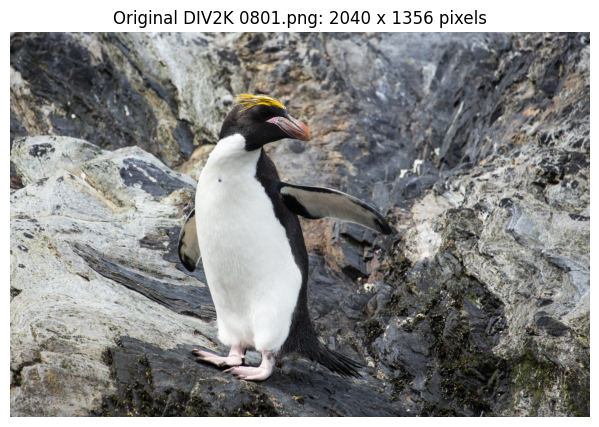

In [18]:
plt.figure(figsize=(8, 5))
plt.imshow(example_x[0].permute(1, 2, 0).numpy())
plt.title(f'Original DIV2K {example_path.name}: {width} x {height} pixels')
plt.axis('off')
plt.show()

## 4. Meet ScaleHyperprior

A basic learned compressor has an **encoder** that makes a compact representation and a **decoder** that
reconstructs an image. ScaleHyperprior also sends a small "hint" describing how to encode that representation.

```text
image x -> encoder g_a -> main representation y -> main bytes ----+
                          |                                      |
                          +-> hyper-encoder h_a -> hint z bytes   |
                                                                 v
            decoded image x_hat <- decoder g_s <- decoded y + hint
```

The hint predicts Gaussian **scales**: roughly, how variable each part of the representation is.
Smooth content and complicated texture need different probability predictions.
Better predictions can reduce the number of encoded bits. The hint itself also costs bits.

### 4.1 Load weights that have already been learned

| Factory argument | Meaning |
|---|---|
| `quality=3` | Select one fixed-rate operating point, from 1 through 8; not a JPEG percentage. |
| `metric='mse'` | Choose weights trained using mean squared error; we can still evaluate other metrics. |
| `pretrained=True` | Load learned weights instead of a random, untrained model. |
| `progress=False` | Hide only the download progress bar, not errors. |

These released weights were trained on **Vimeo90K**, not trained here on DIV2K.
`model.eval()` changes evaluation behavior; it does **not** itself disable gradients.
`model.update()` builds the probability tables needed to encode bytes; it does **not** train the model.

In [19]:
def load_pretrained_codec(quality):
    codec = bmshj2018_hyperprior(
        quality=quality, metric='mse', pretrained=True, progress=False)
    codec = codec.to(CODEC_DEVICE).eval()
    codec.update(force=True)
    return codec

model = load_pretrained_codec(QUALITY)
assert isinstance(model, ScaleHyperprior)
print('Loaded:', type(model).__name__, '| quality:', QUALITY)

Loaded: ScaleHyperprior | quality: 3


### 4.2 What do N and M mean?

A channel is a learned feature map, not necessarily a red/green/blue channel.
**N** controls the hidden and hyperprior channels; **M** is the number of main latent channels.
These counts control network capacity and memory, not the input image's width or height.

`ScaleHyperprior(N=64, M=96)` creates a **random untrained** network.
The factory above chooses widths that match its pretrained weights.
A larger N/M does not guarantee better compression without suitable training.

The table reads actual settings from this installed CompressAI version. Lambda is explained in Part 8.

In [20]:
MSE_LAMBDAS = {1: 0.0018, 2: 0.0035, 3: 0.0067, 4: 0.0130,
               5: 0.0250, 6: 0.0483, 7: 0.0932, 8: 0.1800}
quality_rows = []
for quality, channels in cfgs['bmshj2018-hyperprior'].items():
    quality_rows.append({'quality': quality, 'N': channels[0], 'M': channels[1],
                         'MSE_lambda': MSE_LAMBDAS[quality]})
display(pd.DataFrame(quality_rows))
print('Our N and M:', model.N, model.M)
print('Learned parameters:', f'{sum(p.numel() for p in model.parameters()):,}')

,quality,N,M,MSE_lambda
0,1,128,192,0.0018
1,2,128,192,0.0035
2,3,128,192,0.0067
3,4,128,192,0.0130
4,5,128,192,0.0250
5,6,192,320,0.0483
6,7,192,320,0.0932
7,8,192,320,0.1800


Our N and M: 128 192
Learned parameters: 5,075,843


## 5. Compress and reconstruct the image

### 5.1 Add a small border, if needed

This model repeatedly downsamples its input. Its main representation is downsampled by 16,
and its hint by 64, so encoding needs dimensions divisible by **64**.
We add zeros only on the **right and bottom**; we do not stretch or resize the image.
`(-width) % 64` calculates how many columns are missing from the next multiple of 64.
We remember the original height/width so we can remove this border later.

In [21]:
def pad_to_codec(x, multiple=64):
    original_height, original_width = x.shape[-2:]
    pad_right = (-original_width) % multiple
    pad_bottom = (-original_height) % multiple
    padded = F.pad(x, (0, pad_right, 0, pad_bottom))
    return padded, (original_height, original_width)

example_padded, original_shape = pad_to_codec(example_x, model.downsampling_factor)
print('Original H, W:', original_shape)
print('Padded H, W:', tuple(example_padded.shape[-2:]))

Original H, W: (1356, 2040)
Padded H, W: (1408, 2048)


### 5.2 Inspect a small representation

A **latent** is a learned internal representation. To make its shapes easy to read, inspect a 256 x 256
center crop here. This crop is only an architecture illustration; our compression example still uses
the full image.

`g_a` is the image encoder. `h_a` creates the hint from the magnitude of the main latent.
`torch.inference_mode()` avoids building a gradient graph because we are not training.
For a 256 x 256 input, expect y to be 16 x 16 and z to be 4 x 4 spatially.

In [22]:
architecture_sample = transforms.CenterCrop(CROP_SIZE)(example_x[0]).unsqueeze(0)
with torch.inference_mode():
    y = model.g_a(architecture_sample)
    z = model.h_a(y.abs())
print('Input:', tuple(architecture_sample.shape))
print('Main latent y:', tuple(y.shape))
print('Hint latent z:', tuple(z.shape))

Input: (1, 3, 256, 256)
Main latent y: (1, 192, 16, 16)
Hint latent z: (1, 128, 4, 4)


### 5.3 Understand quantization and the hint

**Quantization** replaces a continuous value with one of a set of discrete values.
Rounding 1.7 to 2 is a simple example. Quantization makes finite bitstreams possible, but loses information.
The actual model also uses learned offsets when quantizing its hint.

`entropy_bottleneck` quantizes and models the hint. `h_s` turns the decoded hint into scales for coding y.
The scale tensor should have the same shape as y. The model handles all of this inside `compress()`.

In [23]:
print('Toy rounding example:', torch.round(torch.tensor([-1.7, -0.2, 0.4, 1.7])))
with torch.inference_mode():
    z_hat, _ = model.entropy_bottleneck(z)
    scales = model.h_s(z_hat)
print('Predicted scales:', tuple(scales.shape))
assert scales.shape == y.shape

Toy rounding example: tensor([-2., -0.,  0.,  2.])
Predicted scales: (1, 192, 16, 16)


### 5.4 Produce actual compressed bytes

`.compress()` performs analysis, quantization, and entropy coding.
Its result contains a dictionary with:
- `strings[0]`: one main y byte string per image in the batch;
- `strings[1]`: one hint z byte string per image;
- `shape`: the hint's spatial dimensions, needed by the decoder.

There is one image in our batch, so `[0]` selects its string.
CPU elapsed time below excludes image loading and display.

In [24]:
start = perf_counter()
with torch.inference_mode():
    example_encoded = model.compress(example_padded)
encode_seconds = perf_counter() - start
print('Result keys:', list(example_encoded.keys()))
print('Hint shape:', tuple(example_encoded['shape']))
print('Encoding seconds:', round(encode_seconds, 3))

Result keys: ['strings', 'shape']
Hint shape: (22, 32)
Encoding seconds: 2.99


### 5.5 Reconstruct from those bytes

The decoder receives **both streams and the hint shape**, plus the shared model weights.
It does not receive the original image pixels.
Encoding and decoding use the same CPU model: floating-point CompressAI bitstreams are not guaranteed
portable across devices or library versions.

In [25]:
start = perf_counter()
with torch.inference_mode():
    decoded = model.decompress(example_encoded['strings'], example_encoded['shape'])
decode_seconds = perf_counter() - start
decoded_padded = decoded['x_hat']
print('Decoded padded shape:', tuple(decoded_padded.shape))
print('Decoding seconds:', round(decode_seconds, 3))

Decoded padded shape: (1, 3, 1408, 2048)
Decoding seconds: 3.392


### 5.6 Remove the added border

The name `x_hat` means "our estimate of x". Slicing `:height, :width` keeps just the original image region.
**Expected:** original and reconstructed tensors have exactly the same shape.
Decoding already clamps pixel values to `[0, 1]`.

In [26]:
example_hat = decoded_padded[:, :, :height, :width]
assert example_hat.shape == example_x.shape
print('Original shape:', tuple(example_x.shape))
print('Reconstructed shape:', tuple(example_hat.shape))
print('Reconstructed range:', example_hat.min().item(), example_hat.max().item())

Original shape: (1, 3, 1356, 2040)
Reconstructed shape: (1, 3, 1356, 2040)
Reconstructed range: 0.0 1.0


## 6. Measure the number of bits and the image quality

### 6.1 Calculate actual bits per pixel

One byte contains **8 bits**. We must count both the main bytes and the hint bytes:

$$\text{payload bpp} = \frac{8(\text{y bytes}+\text{z bytes})}{H W}.$$

Divide by the original number of pixels, **not by 3 channels and not by the padded dimensions**.
Padding still costs bits. Lower bpp means a smaller representation.
This payload rate excludes file headers and the shared model weights.

In [27]:
y_bytes = len(example_encoded['strings'][0][0])
z_bytes = len(example_encoded['strings'][1][0])
payload_bytes = y_bytes + z_bytes
payload_bpp = 8 * payload_bytes / num_pixels
print('Main bytes:', y_bytes, '| hint bytes:', z_bytes)
print('Total payload bytes:', payload_bytes)
print('Actual payload bits per pixel:', round(payload_bpp, 4))
print('Raw RGB / payload size ratio:', round(24 / payload_bpp, 2))

Main bytes: 96984 | hint bytes: 2420
Total payload bytes: 99404
Actual payload bits per pixel: 0.2875
Raw RGB / payload size ratio: 83.48


### 6.2 Calculate MSE and PSNR

MSE averages squared differences over every pixel **and all three color channels**.
Smaller MSE is better. With values in `[0, 1]`:

$$\text{MSE}=\operatorname{mean}((x-\hat{x})^2),\qquad
\text{PSNR}=-10\log_{10}(\text{MSE}).$$

Higher PSNR is better, but it does not fully describe human visual preference.
A perfect reconstruction has MSE=0 and infinite PSNR; the conditional below handles that mathematical limit.

In [28]:
mse = F.mse_loss(example_hat, example_x).item()
psnr_db = -10 * math.log10(mse) if mse > 0 else math.inf
print('MSE:', mse)
print('RGB PSNR:', round(psnr_db, 2), 'dB')

MSE: 0.0007272601942531765
RGB PSNR: 31.38 dB


### 6.3 Measure structural similarity

MS-SSIM compares image structure at several scales rather than only pixel errors.
A score closer to **1** is better. `data_range=1.0` matches our `[0, 1]` tensors.
The default five-scale/window-11 calculation requires each image side to be greater than 160 pixels.

We measure on clamped **floating-point reconstructions**, before rounding to an 8-bit display image.
Benchmark images are never resized to make a metric fit.

In [29]:
assert min(height, width) > 160
ms_ssim_score = ms_ssim(example_x, example_hat, data_range=1.0, size_average=True).item()
print('MS-SSIM:', round(ms_ssim_score, 6))

MS-SSIM: 0.970998


### 6.4 Optional concept: estimated rate is not the same as saved bytes

During training we need a rate calculation that supports gradients. `model(x)` returns reconstructed pixels
and probability estimates called **likelihoods**, but does not create a bitstream.
A value with probability p costs approximately $-\log_2(p)$ bits.
We add those estimated costs for both y and z, then divide by original pixels.

Real byte counts differ because the coder uses finite-precision probability tables and stream termination.
The check also confirms that forward evaluation and actual decoding reconstruct the same pixels.

In [30]:
def likelihood_bpp(likelihoods, num_pixels):
    estimated_bits = sum(-torch.log2(p).sum() for p in likelihoods.values())
    return estimated_bits / num_pixels

with torch.inference_mode():
    example_forward = model(example_padded)
estimated_y_bpp = likelihood_bpp({'y': example_forward['likelihoods']['y']}, num_pixels).item()
estimated_z_bpp = likelihood_bpp({'z': example_forward['likelihoods']['z']}, num_pixels).item()
forward_hat = example_forward['x_hat'][:, :, :height, :width].clamp(0, 1)
torch.testing.assert_close(example_hat, forward_hat, rtol=0, atol=1e-6)
print('Estimated bpp:', round(estimated_y_bpp + estimated_z_bpp, 4), '| actual bpp:', round(payload_bpp, 4))

Estimated bpp: 0.2869 | actual bpp: 0.2875


### 6.5 Put the measurements in one small table

A dictionary gives each result a name; the table shows only the most important numbers for now.
Notice the two separate questions: **How small is the representation? How good is the image?**

In [31]:
example_result = {
    'width': width, 'height': height, 'num_pixels': num_pixels,
    'padded_width': example_padded.shape[-1], 'padded_height': example_padded.shape[-2],
    'estimated_y_bpp': estimated_y_bpp, 'estimated_z_bpp': estimated_z_bpp,
    'estimated_bpp': estimated_y_bpp + estimated_z_bpp,
    'y_bytes': y_bytes, 'z_bytes': z_bytes, 'payload_bytes': payload_bytes,
    'payload_bpp': payload_bpp, 'mse': mse, 'psnr_db': psnr_db, 'ms_ssim': ms_ssim_score,
    'encode_seconds': encode_seconds, 'decode_seconds': decode_seconds,
}
display(pd.DataFrame([example_result])[['width', 'height', 'payload_bpp', 'psnr_db', 'ms_ssim']])

,width,height,payload_bpp,psnr_db,ms_ssim
0,2040,1356,0.287478,31.383102,0.970998


## 7. Inspect what was lost

### 7.1 Compare the original, reconstruction, and error

The third panel is the absolute pixel error multiplied by 8 **only for visibility**.
It is not a new reconstruction and does not change our measurements.
Zoom into texture and edges: where do you expect a low-bitrate model to lose details?

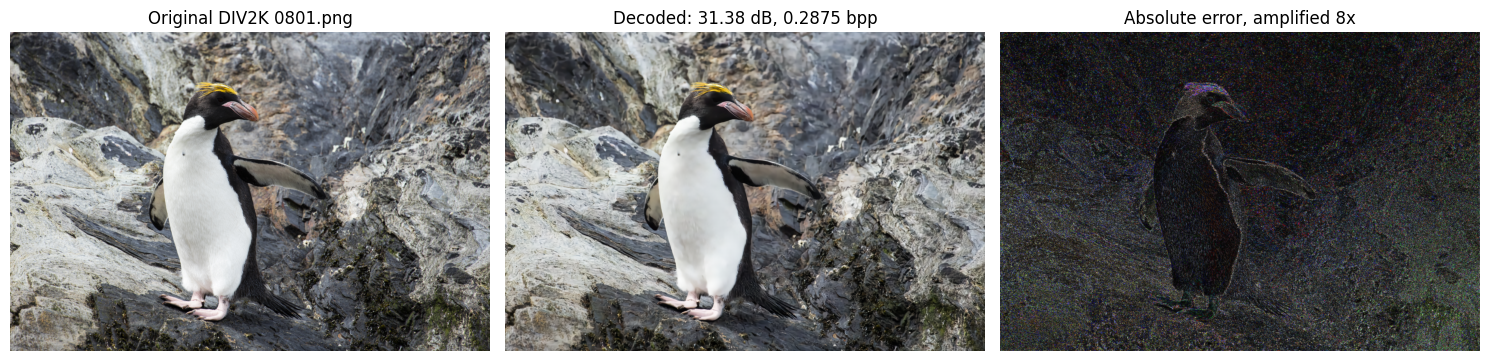

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(example_x[0].permute(1, 2, 0).numpy())
axes[0].set_title('Original DIV2K 0801.png')
axes[1].imshow(example_hat[0].permute(1, 2, 0).numpy())
axes[1].set_title(f'Decoded: {psnr_db:.2f} dB, {payload_bpp:.4f} bpp')
error_picture = (8 * (example_x - example_hat).abs())[0].clamp(0, 1)
axes[2].imshow(error_picture.permute(1, 2, 0).numpy())
axes[2].set_title('Absolute error, amplified 8x')
for axis in axes:
    axis.axis('off')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'div2k_reconstruction_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

### 7.2 Save a picture for viewing

Multiply by 255 and round only when exporting an 8-bit PNG.
**This PNG is not the learned codec's bitstream.** It is a convenient picture of the decoded result.
The model's actual compressed bytes are the y/z strings counted in Part 6.

In [33]:
viewing_pixels = (example_hat[0] * 255).round().to(torch.uint8)
reconstruction_path = OUTPUT_DIR / f'div2k_0801_q{QUALITY}_reconstruction.png'
to_pil_image(viewing_pixels).save(reconstruction_path)
print('Saved viewing image:', reconstruction_path)

Saved viewing image: c:\Users\abdelazm\OneDrive - STMicroelectronics\Myspace\master\Digital_Image\git\Digial_Image_Processing_Project_CSE681\models\outputs\scale_hyperprior\div2k_0801_q3_reconstruction.png


### Pause and check your understanding

You have completed the core image-compression lesson. Explain these before continuing:

1. Why did we add padding instead of resizing the image?
2. Why must we count the hint bytes as well as the main bytes?
3. Does `model(x)` produce an actual compressed file?
4. Which is better: higher or lower bpp? Higher or lower PSNR?

<details><summary>Check your answers</summary>

1. Padding satisfies the model's shape requirement without stretching the original pixels.
2. The decoder needs the hint, so transmitting it has a real cost.
3. No. It gives tensors and likelihoods; `compress()` produces entropy-coded bytes.
4. Lower bpp is smaller; higher PSNR is closer in squared-error terms. Usually one improves at the other's expense.

</details>

**You may stop here on a first reading.** Parts 8-10 build on these same operations; they are not needed
to understand the compression example above.

## 8. Second pass: learn what one training step does

### 8.1 Choose a very small training experiment

**Training** changes weights. **Fine-tuning** starts with pretrained weights rather than random weights.
We fine-tune a separate copy for only 3 steps: enough to demonstrate the mechanics, not to claim improvement.

- **Batch:** the crops used in one update; we use one crop.
- **Step:** one optimizer update.
- **Epoch:** one pass through the training image list, with fresh random crops.
- **Learning rate:** the size of the optimizer's changes, not the image bitrate.

`TRAIN_EPOCHS=2` and `MAX_TRAIN_STEPS=3` mean stop as soon as either limit is reached.
Set `RUN_TRAINING=False` to skip weight updates while keeping pretrained evaluation.

In [34]:
from torch.utils.data import Dataset, DataLoader
from compressai.losses import RateDistortionLoss
from compressai.optimizers import net_aux_optimizer

RUN_TRAINING = True
BATCH_SIZE = 1
TRAIN_EPOCHS = 2
MAX_TRAIN_STEPS = 3
MAIN_LR = 1e-4
AUX_LR = 1e-3
CLIP_MAX_NORM = 1.0
LAMBDA = MSE_LAMBDAS[QUALITY]
TRAIN_DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Training device:', TRAIN_DEVICE)

Training device: cuda


### 8.2 Choose how to make a crop

A full DIV2K image is large; random 256 x 256 crops use less memory and expose different regions over time.
A random horizontal flip adds a simple variation. These operations do not resize an image.
Validation instead uses a **fixed center crop** so repeated loss checks use the same pixels.
Full-image evaluation in Parts 5-7 and 9 is separate from this crop-based training check.

In [35]:
train_transform = transforms.Compose([
    transforms.RandomCrop(CROP_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])
valid_transform = transforms.Compose([
    transforms.CenterCrop(CROP_SIZE),
    transforms.ToTensor(),
])

### 8.3 Tell PyTorch how to read one training example

A `Dataset` is a collection with two main operations:
`__len__` says how many images exist, and `__getitem__` returns one transformed image.
`self.paths` and `self.transform` remember the filenames and crop instructions.
Each call applies the transform again, so a training image can produce a new crop.

In [36]:
class DIV2KCrops(Dataset):
    def __init__(self, paths, transform):
        self.paths = list(paths)
        self.transform = transform
        if not self.paths:
            raise FileNotFoundError('DIV2K split is empty. Check Part 2.')

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        verify_rgb_png(self.paths[index])
        with Image.open(self.paths[index]) as image:
            if min(image.size) < CROP_SIZE:
                raise ValueError(f'Image is smaller than the required crop: {self.paths[index]}')
            return self.transform(image.convert('RGB'))

### 8.4 Make batches, without mixing the splits

A `DataLoader` collects examples into batches. `shuffle=True` changes the training image order.
`num_workers=0` is a simple choice that works reliably in Windows notebooks.
The check below prevents validation images from appearing in the training list.
Uncapped training requires the complete 800/100 DIV2K splits; a tiny example must not silently become "full training".

In [37]:
assert BATCH_SIZE > 0 and TRAIN_EPOCHS > 0 and CROP_SIZE == 256
assert MAX_TRAIN_STEPS is None or MAX_TRAIN_STEPS > 0
train_data = DIV2KCrops(DATA_PATHS['DIV2K train'], train_transform)
valid_data = DIV2KCrops(DATA_PATHS['DIV2K validation'], valid_transform)
assert set(p.name for p in train_data.paths).isdisjoint(p.name for p in valid_data.paths)
if MAX_TRAIN_STEPS is None:
    for label in ('DIV2K train', 'DIV2K validation'):
        if len(DATA_PATHS[label]) != len(EXPECTED_NAMES[label]):
            raise ValueError(f'Uncapped training requires the complete {label} split.')
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                          generator=torch.Generator().manual_seed(SEED))
valid_loader = DataLoader(valid_data, batch_size=1, shuffle=False, num_workers=0)
print('Training images:', len(train_data), '| validation images:', len(valid_data))

Training images: 2 | validation images: 1


### 8.5 See the random crops before training

The four panels come from the same training image, but each read samples a crop again.
Expect `(3, 256, 256)` float tensors in `[0, 1]`.
Random crops can sometimes overlap; they do not create four independent source images.

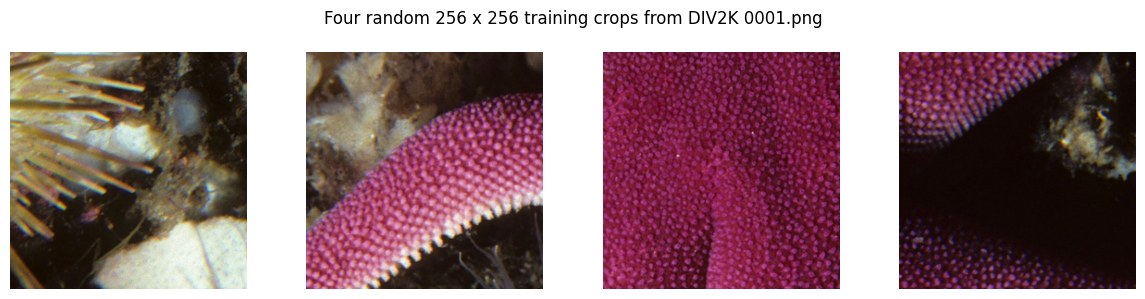

In [38]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for axis in axes:
    crop = train_data[0]
    assert crop.shape == (3, 256, 256) and crop.dtype == torch.float32
    assert 0 <= crop.min() <= crop.max() <= 1
    axis.imshow(crop.permute(1, 2, 0).numpy())
    axis.axis('off')
fig.suptitle('Four random 256 x 256 training crops from DIV2K 0001.png')
plt.tight_layout()
plt.show()

### 8.6 Define what the model tries to minimize

We want a small representation **and** a good reconstruction:

$$\text{loss} = \text{estimated bpp} + \lambda\,255^2\,\text{MSE}.$$

Lambda sets the importance of image error relative to rate. Larger lambda favors reconstruction quality.
The factor $255^2$ is part of CompressAI's MSE convention; dropping it changes the meaning of lambda.
We use the existing `RateDistortionLoss`, which includes the y and z rates.

**Training uses `model(batch)`, not `compress()`:** gradients can pass through the training approximation
of quantization. Exact byte coding is for later evaluation.

In [39]:
criterion = RateDistortionLoss(lmbda=LAMBDA, metric='mse')
print('Lambda:', LAMBDA)
print('Objective: estimated bpp + lambda * 255**2 * MSE')

Lambda: 0.0067
Objective: estimated bpp + lambda * 255**2 * MSE


### 8.7 Measure validation loss without changing weights

This helper evaluates each fixed validation crop and averages the three loss components.
`inference_mode` means no gradient graph; `.eval()` must also be selected on the model.
Validation data is never sent to an optimizer.

In [40]:
@torch.inference_mode()
def validation_loss(codec):
    if codec.training:
        raise ValueError('Select eval mode before validation.')
    device = next(codec.parameters()).device
    totals = {'loss': 0.0, 'bpp_loss': 0.0, 'mse_loss': 0.0}
    count = 0
    for batch in valid_loader:
        batch = batch.to(device)
        losses = criterion(codec(batch), batch)
        for key in totals:
            totals[key] += losses[key].item() * batch.shape[0]
        count += batch.shape[0]
    return {key: value / count for key, value in totals.items()}

### 8.8 Keep the pretrained reference unchanged

`deepcopy` makes an independent copy. We will compare it with the unchanged pretrained model afterward.
The **main optimizer** updates the image transforms and probability-model parameters.
The **auxiliary optimizer** updates only entropy-bottleneck quantiles, which help set the coder's probability range.
Its auxiliary loss is not an additional image-quality error.

In [41]:
training_model = None
optimizers = None
before_validation = None
restored_model = None
checkpoint_path = None
if RUN_TRAINING:
    before_validation = validation_loss(model)
    training_model = copy.deepcopy(model).to(TRAIN_DEVICE)
    optimizers = net_aux_optimizer(training_model, {
        'net': {'type': 'Adam', 'lr': MAIN_LR},
        'aux': {'type': 'Adam', 'lr': AUX_LR},
    })
    print('Starting validation loss:', before_validation)

Starting validation loss: {'loss': 0.3875139653682709, 'bpp_loss': 0.17243137955665588, 'mse_loss': 0.0004936851910315454}


### 8.9 Check that the optimizers do not update the same parameters

A parameter must belong to exactly one optimizer. `id(p)` identifies a particular parameter object.
The first assertion checks no overlap; the second checks that every trainable parameter is covered.
This is a safety check; CompressAI's helper performs the partition for us.

In [42]:
if RUN_TRAINING:
    main_ids = {id(p) for group in optimizers['net'].param_groups for p in group['params']}
    aux_ids = {id(p) for group in optimizers['aux'].param_groups for p in group['params']}
    assert not main_ids & aux_ids
    assert main_ids | aux_ids == {id(p) for p in training_model.parameters() if p.requires_grad}
    print('Main parameter tensors:', len(main_ids), '| auxiliary tensors:', len(aux_ids))

Main parameter tensors: 54 | auxiliary tensors: 1


### 8.10 Write the instructions for ONE training step

Read these operations in order:
1. Clear gradients left over from the previous step.
2. Predict a reconstruction and calculate the rate-distortion loss.
3. `backward()` calculates how each parameter affects the loss.
4. Clip very large gradients, then the main optimizer's `.step()` changes its parameters.
5. Calculate the auxiliary loss, backpropagate it, and update the quantiles with the auxiliary optimizer.

This function only defines the instructions. **Training starts in the next cell.**
Non-finite losses/gradients stop execution instead of quietly producing a broken model.

In [43]:
def train_one_step(batch):
    batch = batch.to(TRAIN_DEVICE)
    assert batch.shape[1:] == (3, 256, 256)
    optimizers['net'].zero_grad(set_to_none=True)
    optimizers['aux'].zero_grad(set_to_none=True)
    losses = criterion(training_model(batch), batch)
    if not torch.isfinite(losses['loss']):
        raise FloatingPointError('Non-finite rate-distortion loss.')
    losses['loss'].backward()
    torch.nn.utils.clip_grad_norm_(training_model.parameters(), CLIP_MAX_NORM, error_if_nonfinite=True)
    optimizers['net'].step()
    auxiliary_loss = training_model.aux_loss()
    if not torch.isfinite(auxiliary_loss):
        raise FloatingPointError('Non-finite auxiliary loss.')
    auxiliary_loss.backward()
    optimizers['aux'].step()
    return {'loss': losses['loss'].item(), 'estimated_bpp': losses['bpp_loss'].item(),
            'mse': losses['mse_loss'].item(), 'aux_loss': auxiliary_loss.item()}

### 8.11 Repeat the step, but stop after three updates

The outer loop counts epochs; the inner loop visits batches.
We record one row per update and stop at the step limit even if an epoch is unfinished.
`.train()` enables training behavior, including the differentiable quantization approximation.
CUDA timing is synchronized before reporting elapsed training time.

Each row may use a different crop, so its loss can rise or fall. Three steps are not a convergence test.

In [44]:
train_history_rows = []
training_seconds = 0.0
if RUN_TRAINING:
    start_training = perf_counter()
    for epoch in range(TRAIN_EPOCHS):
        training_model.train()
        for batch in train_loader:
            row = train_one_step(batch)
            row.update(step=len(train_history_rows) + 1, epoch=epoch + 1)
            train_history_rows.append(row)
            print(f"Step {row['step']}: loss={row['loss']:.4f}, rate={row['estimated_bpp']:.4f} bpp")
            if MAX_TRAIN_STEPS is not None and len(train_history_rows) >= MAX_TRAIN_STEPS:
                break
        if MAX_TRAIN_STEPS is not None and len(train_history_rows) >= MAX_TRAIN_STEPS:
            break
    if TRAIN_DEVICE.type == 'cuda':
        torch.cuda.synchronize()
    training_seconds = perf_counter() - start_training
else:
    print('Training explicitly disabled; only pretrained results will be evaluated.')

Step 1: loss=0.8537, rate=0.4350 bpp
Step 2: loss=0.8579, rate=0.4014 bpp


Step 3: loss=0.9590, rate=0.4549 bpp


### 8.12 Return to evaluation and refresh the coder

After learning, select CPU/eval again and refresh the integer probability tables with `update`.
Compare validation loss on the **same fixed crops** as before training.
A three-step fine-tune can make results worse; we do not claim that it improves the model.

In [45]:
validation_comparison = None
if RUN_TRAINING:
    training_model = training_model.to(CODEC_DEVICE).eval()
    training_model.update(force=True)
    after_validation = validation_loss(training_model)
    validation_comparison = pd.DataFrame(
        [before_validation, after_validation],
        index=['pretrained', f'fine-tuned {len(train_history_rows)} steps'])
    display(validation_comparison)
    validation_comparison.to_csv(OUTPUT_DIR / 'center_crop_validation.csv')
    print('Training seconds:', round(training_seconds, 2))

,loss,bpp_loss,mse_loss
pretrained,0.387514,0.172431,0.000494
fine-tuned 3 steps,0.518008,0.182048,0.000771


Training seconds: 1.38


### 8.13 Inspect the short training trace

These plots show the recorded objective, estimated rate, and auxiliary loss.
The horizontal axis counts optimizer steps, not epochs.
The CSV preserves the exact values; three points demonstrate the code path, not stable training behavior.

,loss,estimated_bpp,mse,aux_loss,step,epoch
0,0.853713,0.435039,0.000961,232.767181,1,1
1,0.857861,0.401444,0.001048,1544.612793,2,1
2,0.958973,0.454866,0.001157,1392.550293,3,2


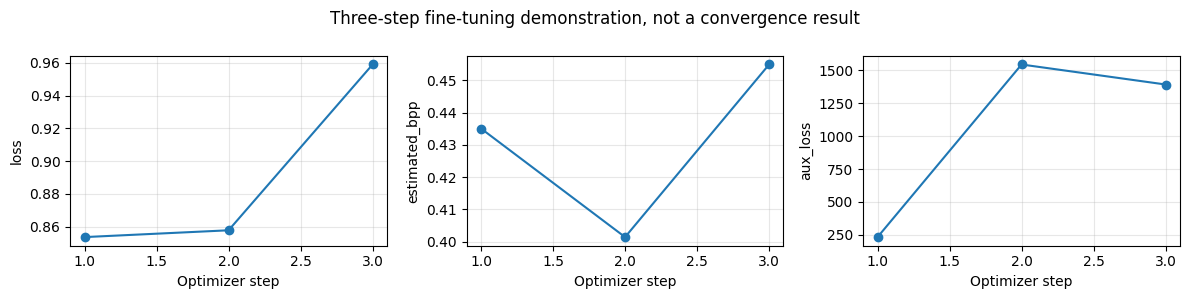

In [46]:
if RUN_TRAINING:
    train_history = pd.DataFrame(train_history_rows)
    train_history.to_csv(OUTPUT_DIR / 'training_history.csv', index=False)
    display(train_history)
    fig, axes = plt.subplots(1, 3, figsize=(12, 3))
    for axis, column in zip(axes, ['loss', 'estimated_bpp', 'aux_loss']):
        axis.plot(train_history['step'], train_history[column], marker='o')
        axis.set(xlabel='Optimizer step', ylabel=column)
        axis.grid(alpha=0.3)
    fig.suptitle('Three-step fine-tuning demonstration, not a convergence result')
    plt.tight_layout()
    plt.show()

### 8.14 Save learned weights and experiment settings

A **checkpoint** is a saved training state, not a compressed image.
`state_dict()` contains the model's parameters and buffers. Optimizer states let a later experiment
restore the optimizers too. We also record which images and settings produced the checkpoint.
This cell runs only when training is enabled.

In [47]:
if RUN_TRAINING:
    checkpoint_path = OUTPUT_DIR / 'div2k_finetuned_checkpoint.pth'
    checkpoint = {
        'state_dict': training_model.state_dict(), 'N': training_model.N, 'M': training_model.M,
        'initial_pretrained_quality': QUALITY, 'lambda': LAMBDA, 'seed': SEED,
        'steps': len(train_history_rows), 'epochs_started': epoch + 1, 'crop_size': CROP_SIZE,
        'train_filenames': [p.name for p in train_data.paths],
        'validation_filenames': [p.name for p in valid_data.paths],
        'net_optimizer': optimizers['net'].state_dict(),
        'aux_optimizer': optimizers['aux'].state_dict(),
    }
    torch.save(checkpoint, checkpoint_path)
    print('Saved checkpoint:', checkpoint_path)

Saved checkpoint: c:\Users\abdelazm\OneDrive - STMicroelectronics\Myspace\master\Digital_Image\git\Digial_Image_Processing_Project_CSE681\models\outputs\scale_hyperprior\div2k_finetuned_checkpoint.pth


### 8.15 Reload into a new model

Reopening a checkpoint tests more than checking that a file exists.
`map_location='cpu'` loads tensors on the CPU; `weights_only=True` limits the kinds of objects loaded.
`from_state_dict` reconstructs the model widths from its weights.
Only load checkpoints you trust; this one was just created by this notebook.

In [48]:
if RUN_TRAINING:
    saved_checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
    restored_model = ScaleHyperprior.from_state_dict(saved_checkpoint['state_dict']).to(CODEC_DEVICE).eval()
    restored_model.update(force=True)
    print('Restored widths:', restored_model.N, restored_model.M)

Restored widths: 128 192


### 8.16 Confirm that the restored model really encodes and decodes

Encode the same validation crop with both copies, then decode it.
Their reconstructed tensors and byte counts must agree exactly.
We keep the restored CPU model for evaluation and release the extra training/optimizer objects.

In [49]:
if RUN_TRAINING:
    validation_crop = valid_data[0].unsqueeze(0)
    with torch.inference_mode():
        trained_stream = training_model.compress(validation_crop)
        restored_stream = restored_model.compress(validation_crop)
        trained_hat = training_model.decompress(trained_stream['strings'], trained_stream['shape'])['x_hat']
        restored_hat = restored_model.decompress(restored_stream['strings'], restored_stream['shape'])['x_hat']
    torch.testing.assert_close(restored_hat, trained_hat, rtol=0, atol=0)
    assert restored_stream['strings'] == trained_stream['strings']
    print('Checkpoint round-trip check passed.')
    del checkpoint, saved_checkpoint, training_model, optimizers
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Checkpoint round-trip check passed.


## 9. Evaluate on Kodak and Tecnick

We have already done the image-to-bytes-to-image process one operation at a time.
Now we put the same operations into small functions so we can repeat them on other images.
**There is no new compression algorithm in these helpers.**

### 9.1 Reuse loading and input checks

Evaluation expects one RGB image, values in `[0, 1]`, and a CPU model in eval mode.
Bad inputs raise an error instead of returning a plausible but incorrect score.

In [50]:
def load_rgb_tensor(path):
    verify_rgb_png(path)
    with Image.open(path) as image:
        return to_tensor(image).unsqueeze(0).to(CODEC_DEVICE)

def check_evaluation_input(codec, x):
    if codec.training or next(codec.parameters()).device.type != 'cpu' or x.device.type != 'cpu':
        raise ValueError('Use an eval-mode CPU model and CPU tensor.')
    if x.ndim != 4 or x.shape[0] != 1 or x.shape[1] != 3:
        raise ValueError('Expected one RGB image: 1 x 3 x H x W.')
    if not torch.isfinite(x).all() or x.min() < 0 or x.max() > 1:
        raise ValueError('Input must contain finite RGB values in [0, 1].')

### 9.2 Reuse our image-quality measurements

This function repeats the MSE, PSNR, and MS-SSIM calculations from Part 6.
Matching shapes ensure that we compare the same pixel locations, after padding has been removed.
The small-image check explains MS-SSIM's limit instead of secretly resizing an image.

In [51]:
def distortion_metrics(x, x_hat):
    if x.shape != x_hat.shape or x.ndim != 4 or x.shape[0:2] != (1, 3):
        raise ValueError('Metrics require matching 1 x 3 x H x W tensors.')
    if min(x.shape[-2:]) <= 160:
        raise ValueError('Five-scale MS-SSIM needs H and W > 160; do not resize benchmark images.')
    if not torch.isfinite(x).all() or not torch.isfinite(x_hat).all():
        raise ValueError('Non-finite pixels in metric input.')
    error = F.mse_loss(x_hat, x).item()
    return {
        'mse': error,
        'psnr_db': -10 * math.log10(error) if error > 0 else math.inf,
        'ms_ssim': ms_ssim(x, x_hat, data_range=1.0, size_average=True).item(),
    }

### 9.3 Reuse real coding and timing

This helper combines the two operations we timed in Part 5. It returns the streams, padded reconstruction,
and the two elapsed times. It does not load files or calculate image-quality metrics.
The decorator disables gradients whenever the helper is called.

In [52]:
@torch.inference_mode()
def encode_decode(codec, padded):
    start = perf_counter()
    encoded = codec.compress(padded)
    encode_time = perf_counter() - start
    start = perf_counter()
    reconstruction = codec.decompress(encoded['strings'], encoded['shape'])['x_hat']
    decode_time = perf_counter() - start
    return encoded, reconstruction, encode_time, decode_time

### 9.4 Assemble the same evaluation recipe

Read the function as a checklist:
**check -> pad -> estimate -> encode/decode -> unpad -> count bytes -> measure quality**.
`result.update(...)` adds named values to the results dictionary.
We check forward and real-decode agreement for every image, not only for the first example.

The helper includes padded coding costs but divides by original H x W, exactly as we did by hand.

In [53]:
@torch.inference_mode()
def evaluate_tensor(codec, x):
    check_evaluation_input(codec, x)
    padded, (h, w) = pad_to_codec(x, codec.downsampling_factor)
    forward = codec(padded)
    rates = {name: likelihood_bpp({name: p}, h * w).item()
             for name, p in forward['likelihoods'].items()}
    encoded, reconstruction, encode_time, decode_time = encode_decode(codec, padded)
    x_hat = reconstruction[:, :, :h, :w]
    torch.testing.assert_close(x_hat, forward['x_hat'][:, :, :h, :w].clamp(0, 1), rtol=0, atol=1e-6)
    main_bytes = sum(len(s) for s in encoded['strings'][0])
    hint_bytes = sum(len(s) for s in encoded['strings'][1])
    result = {
        'width': w, 'height': h, 'num_pixels': h * w,
        'padded_width': padded.shape[-1], 'padded_height': padded.shape[-2],
        'estimated_y_bpp': rates['y'], 'estimated_z_bpp': rates['z'],
        'estimated_bpp': rates['y'] + rates['z'],
        'y_bytes': main_bytes, 'z_bytes': hint_bytes, 'payload_bytes': main_bytes + hint_bytes,
        'payload_bpp': 8 * (main_bytes + hint_bytes) / (h * w),
        'encode_seconds': encode_time, 'decode_seconds': decode_time,
    }
    result.update(distortion_metrics(x, x_hat))
    return result, encoded, x_hat

### 9.5 Choose a demo subset, not a pretend full benchmark

Leave the flag False to evaluate one original image from each benchmark.
If you enable full evaluation, **all 24 Kodak and all 100 Tecnick images must exist**.
Missing data raises an error; the notebook never silently falls back to a subset.
No benchmark image is resized, cropped, or used for training. We check its original dimensions too,
so a resized file cannot accidentally be reported as an original-resolution benchmark image.

In [54]:
RUN_FULL_EVALUATION = False
DEMO_EVAL_IMAGES = 1
assert DEMO_EVAL_IMAGES > 0
EVAL_PATHS = {}
for label in ('Kodak', 'Tecnick'):
    if RUN_FULL_EVALUATION:
        missing = [name for name in EXPECTED_NAMES[label] if not (DATA_DIRS[label] / name).is_file()]
        if missing:
            raise FileNotFoundError(f'Full {label} evaluation needs {len(EXPECTED_NAMES[label])} images; missing {len(missing)}.')
        EVAL_PATHS[label] = [DATA_DIRS[label] / name for name in EXPECTED_NAMES[label]]
    else:
        EVAL_PATHS[label] = DATA_PATHS[label][:DEMO_EVAL_IMAGES]
    if not EVAL_PATHS[label]:
        raise FileNotFoundError(f'No evaluation images for {label}.')
    expected_sizes = [(512, 768), (768, 512)] if label == 'Kodak' else [(1200, 1200)]
    for path in EVAL_PATHS[label]:
        verify_rgb_png(path)
        with Image.open(path) as image:
            if image.size not in expected_sizes:
                raise ValueError(f'Wrong original {label} resolution: {path}: {image.size}')
    print(label, f'{len(EVAL_PATHS[label])}/{len(EXPECTED_NAMES[label])}',
          'FULL BENCHMARK' if RUN_FULL_EVALUATION else 'SUBSET DEMONSTRATION')

Kodak 1/24 SUBSET DEMONSTRATION
Tecnick 1/100 SUBSET DEMONSTRATION


### 9.6 Repeat evaluation for a list of filenames

The first small image warms up the coder and is excluded from reported times.
The loop then loads and evaluates each original image and adds its name to the results.
These timings exclude file loading, the estimated-rate forward pass, and metric computation.
They describe this machine; they are not a calibrated hardware comparison.

In [55]:
def evaluate_paths(codec, paths, dataset, model_label, quality):
    with torch.inference_mode():
        warm = codec.compress(torch.zeros(1, 3, 256, 256, device=CODEC_DEVICE))
        codec.decompress(warm['strings'], warm['shape'])
    rows = []
    for index, path in enumerate(paths, 1):
        result, _, _ = evaluate_tensor(codec, load_rgb_tensor(path))
        result.update(dataset=dataset, model=model_label, quality=quality, image=path.name,
                      evaluation_scope='full' if RUN_FULL_EVALUATION else 'subset')
        rows.append(result)
        print(f"{dataset} [{index}/{len(paths)}] {path.name}: "
              f"{result['payload_bpp']:.4f} bpp, {result['psnr_db']:.2f} dB", flush=True)
    return rows

### 9.7 Compare pretrained and briefly fine-tuned weights

Each model sees exactly the same evaluation filenames.
The model names distinguish a released pretrained checkpoint from our short DIV2K fine-tune.
A three-step model can be worse than the original; that is a valid result, not a reason to hide a row.

In [56]:
reference_label = f'pretrained_q{QUALITY}'
benchmark_codecs = {reference_label: model}
if restored_model is not None:
    benchmark_codecs[f'DIV2K_finetuned_{len(train_history_rows)}_steps'] = restored_model
benchmark_rows = []
for model_label, codec in benchmark_codecs.items():
    for label, paths in EVAL_PATHS.items():
        benchmark_rows.extend(evaluate_paths(codec, paths, label, model_label, QUALITY))
benchmark_results = pd.DataFrame(benchmark_rows)
display(benchmark_results[['dataset', 'model', 'image', 'payload_bpp', 'psnr_db', 'ms_ssim']])

Kodak [1/1] kodim01.png: 0.5278 bpp, 28.70 dB


Tecnick [1/1] RGB_OR_1200x1200_001.png: 0.1795 bpp, 34.04 dB


Kodak [1/1] kodim01.png: 0.5070 bpp, 27.95 dB


Tecnick [1/1] RGB_OR_1200x1200_001.png: 0.1871 bpp, 30.73 dB


,dataset,model,image,payload_bpp,psnr_db,ms_ssim
0,Kodak,pretrained_q3,kodim01.png,0.527751,28.695193,0.966873
1,Tecnick,pretrained_q3,RGB_OR_1200x1200_001.png,0.179511,34.036745,0.982229
2,Kodak,DIV2K_finetuned_3_steps,kodim01.png,0.506999,27.953866,0.960544
3,Tecnick,DIV2K_finetuned_3_steps,RGB_OR_1200x1200_001.png,0.187133,30.733207,0.977672


### 9.8 Summarize each dataset separately

We normally report the **mean of per-image** PSNR, MS-SSIM, and bpp.
Mean PSNR is not the same as calculating PSNR from one pooled MSE.
We also retain pixel-weighted bpp: $8\sum B/\sum HW$; do not mix that convention with mean bpp.
With one image, both bpp averages are equal.
Always report `n_images` next to the complete dataset size.

In [57]:
summary_rows = []
for (dataset, model_label), group in benchmark_results.groupby(['dataset', 'model'], sort=False):
    summary_rows.append({
        'dataset': dataset, 'model': model_label, 'n_images': len(group),
        'full_set_size': len(EXPECTED_NAMES[dataset]),
        'evaluation_scope': 'full' if RUN_FULL_EVALUATION else 'subset',
        'mean_psnr_db': group['psnr_db'].mean(), 'mean_ms_ssim': group['ms_ssim'].mean(),
        'mean_payload_bpp': group['payload_bpp'].mean(),
        'pixel_weighted_payload_bpp': 8 * group['payload_bytes'].sum() / group['num_pixels'].sum(),
        'mean_estimated_bpp': group['estimated_bpp'].mean(),
        'mean_encode_seconds': group['encode_seconds'].mean(),
        'mean_decode_seconds': group['decode_seconds'].mean(),
    })
benchmark_summary = pd.DataFrame(summary_rows)
display(benchmark_summary[['dataset', 'model', 'n_images', 'full_set_size',
                           'mean_payload_bpp', 'mean_psnr_db', 'mean_ms_ssim']])
benchmark_results.to_csv(OUTPUT_DIR / 'benchmark_per_image.csv', index=False)
benchmark_summary.to_csv(OUTPUT_DIR / 'benchmark_summary.csv', index=False)

,dataset,model,n_images,full_set_size,mean_payload_bpp,mean_psnr_db,mean_ms_ssim
0,Kodak,pretrained_q3,1,24,0.527751,28.695193,0.966873
1,Tecnick,pretrained_q3,1,100,0.179511,34.036745,0.982229
2,Kodak,DIV2K_finetuned_3_steps,1,24,0.506999,27.953866,0.960544
3,Tecnick,DIV2K_finetuned_3_steps,1,100,0.187133,30.733207,0.977672


## 10. Compare bitrate and quality

### 10.1 Select several pretrained operating points

To change the rate of this fixed-rate model, load another pretrained quality checkpoint.
Changing lambda **without retraining** does not change the bits produced by the same weights.
Qualities 1, 3, and 5 are a useful small comparison; extra weights download only once to the PyTorch cache.
Set `RUN_RD_SWEEP=False` to skip this optional comparison.

In [58]:
RUN_RD_SWEEP = True
RD_QUALITIES = (1, 3, 5)
rd_rows = []
rd_points = pd.DataFrame()

### 10.2 Evaluate the same images at each quality

Reuse the pretrained q=3 results we already calculated; load q=1 and q=5 separately.
The fine-tuned model is **not** mixed into these pretrained curves.
For a fair comparison, every quality sees the same images and uses the same metric settings.

In [59]:
if RUN_RD_SWEEP:
    for quality in RD_QUALITIES:
        if quality == QUALITY:
            existing = benchmark_results[benchmark_results['model'] == reference_label]
            rd_rows.extend(existing.to_dict('records'))
        else:
            sweep_codec = load_pretrained_codec(quality)
            for label, paths in EVAL_PATHS.items():
                rd_rows.extend(evaluate_paths(sweep_codec, paths, label, f'pretrained_q{quality}', quality))
            del sweep_codec
else:
    print('Quality sweep explicitly disabled.')

Kodak [1/1] kodim01.png: 0.2039 bpp, 25.34 dB


Tecnick [1/1] RGB_OR_1200x1200_001.png: 0.0898 bpp, 30.64 dB


Kodak [1/1] kodim01.png: 1.0983 bpp, 32.72 dB


Tecnick [1/1] RGB_OR_1200x1200_001.png: 0.3412 bpp, 37.76 dB


### 10.3 Make one point per dataset and quality

`groupby` collects rows with the same dataset and quality.
We count the images and average the measurements, then save both the detailed and summarized tables.
In demo mode each point represents **one image**, not the whole dataset.

In [60]:
if RUN_RD_SWEEP:
    rd_results = pd.DataFrame(rd_rows)
    rd_points = rd_results.groupby(['dataset', 'quality'], as_index=False).agg(
        n_images=('image', 'count'), payload_bpp=('payload_bpp', 'mean'),
        psnr_db=('psnr_db', 'mean'), ms_ssim=('ms_ssim', 'mean'))
    rd_points['evaluation_scope'] = 'full' if RUN_FULL_EVALUATION else 'subset'
    display(rd_points)
    rd_results.to_csv(OUTPUT_DIR / 'rate_distortion_per_image.csv', index=False)
    rd_points.to_csv(OUTPUT_DIR / 'rate_distortion_points.csv', index=False)

,dataset,quality,n_images,payload_bpp,psnr_db,ms_ssim,evaluation_scope
0,Kodak,1,1,0.203857,25.342371,0.915947,subset
1,Kodak,3,1,0.527751,28.695193,0.966873,subset
2,Kodak,5,1,1.098307,32.716572,0.988092,subset
3,Tecnick,1,1,0.089778,30.639194,0.967044,subset
4,Tecnick,3,1,0.179511,34.036745,0.982229,subset
5,Tecnick,5,1,0.341200,37.761868,0.992113,subset


### 10.4 Read a rate-distortion curve

**Left-to-right:** more actual payload bits per pixel. **Upward:** better reconstruction quality.
For the same image collection, a desirable model is higher at the same rate, or farther left at the same quality.
Here the labels show different pretrained operating points of the same architecture.
Different dataset curves also reflect different image contents, not just model ability.

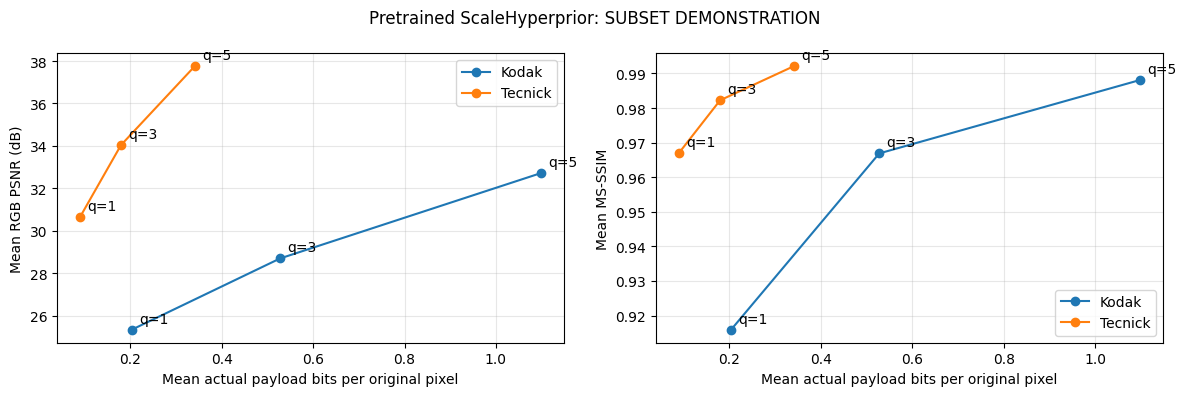

In [61]:
if RUN_RD_SWEEP:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for label, group in rd_points.groupby('dataset'):
        group = group.sort_values('payload_bpp')
        for axis, metric in zip(axes, ['psnr_db', 'ms_ssim']):
            axis.plot(group['payload_bpp'], group[metric], marker='o', label=label)
            for _, point in group.iterrows():
                axis.annotate(f"q={int(point['quality'])}", (point['payload_bpp'], point[metric]),
                              xytext=(5, 5), textcoords='offset points')
    for axis, ylabel in zip(axes, ['Mean RGB PSNR (dB)', 'Mean MS-SSIM']):
        axis.set(xlabel='Mean actual payload bits per original pixel', ylabel=ylabel)
        axis.grid(alpha=0.3)
        axis.legend()
    scope_title = 'full benchmarks' if RUN_FULL_EVALUATION else 'SUBSET DEMONSTRATION'
    fig.suptitle('Pretrained ScaleHyperprior: ' + scope_title)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / 'rate_distortion_curves.png', dpi=140, bbox_inches='tight')
    plt.show()

## Optional appendix: saving, checking, and larger experiments

The main learning path is complete. The following small cells preserve practical experiment features,
but you can skip studying them until you understand Parts 1-10.
They also execute with **Run All** and write useful files.

### A.1 Save the actual bytes, not only a PNG

Our small educational `.shp` container has two parts:
1. A **32-byte header**: magic `SHP1`, pretrained quality, original H/W, hint H/W, and y/z lengths.
2. The exact y and z byte strings.

`struct` packs integers into a defined binary format. `>4s7I` means big-endian, 4 text bytes, then 7 four-byte integers.
This format is only for our **pretrained MSE example**. It requires matching model weights, CompressAI version,
ANS implementation, and CPU environment. It is not a portable compression standard or a fine-tuned model identifier.

In [62]:
BITSTREAM_HEADER = struct.Struct('>4s7I')
z_height, z_width = example_encoded['shape']
y_string = example_encoded['strings'][0][0]
z_string = example_encoded['strings'][1][0]
header = BITSTREAM_HEADER.pack(
    b'SHP1', QUALITY, height, width, z_height, z_width, len(y_string), len(z_string))
bitstream_path = OUTPUT_DIR / f'div2k_0801_q{QUALITY}.shp'
bitstream_path.write_bytes(header + y_string + z_string)
example_file_bpp = 8 * bitstream_path.stat().st_size / num_pixels
print('Payload bpp:', payload_bpp, '| file bpp including header:', example_file_bpp)

Payload bpp: 0.2874775869049685 | file bpp including header: 0.2875701312973567


### A.2 Read the header and split the saved bytes

The header tells us where the main stream ends and the hint stream begins.
Checks reject a wrong identifier/quality or an inconsistent file length.
The decoder needs the original dimensions to remove padding, but no original pixels.

In [63]:
file_bytes = bitstream_path.read_bytes()
magic, saved_quality, saved_h, saved_w, saved_zh, saved_zw, y_length, z_length = BITSTREAM_HEADER.unpack_from(file_bytes)
assert magic == b'SHP1' and saved_quality == QUALITY
assert len(file_bytes) == BITSTREAM_HEADER.size + y_length + z_length
offset = BITSTREAM_HEADER.size
saved_strings = [[file_bytes[offset:offset + y_length]], [file_bytes[offset + y_length:]]]
print('Header bytes:', BITSTREAM_HEADER.size, '| total file bytes:', len(file_bytes))

Header bytes: 32 | total file bytes: 99436


### A.3 Decode the saved file and compare

This call uses the strings and dimensions read from disk.
Matching the earlier in-memory reconstruction proves that saving did not lose or reorder the bytes.
File bpp includes the header; neither payload nor file bpp includes shared model weights.

In [64]:
with torch.inference_mode():
    file_decoded = model.decompress(saved_strings, (saved_zh, saved_zw))['x_hat']
file_decoded = file_decoded[:, :, :saved_h, :saved_w]
torch.testing.assert_close(file_decoded, example_hat, rtol=0, atol=0)
display(pd.DataFrame([{'payload_bytes': payload_bytes, 'header_bytes': BITSTREAM_HEADER.size,
                       'file_bytes': len(file_bytes), 'payload_bpp': payload_bpp,
                       'file_bpp': example_file_bpp}]))
print('Saved-file decoding check passed.')

,payload_bytes,header_bytes,file_bytes,payload_bpp,file_bpp
0,99404,32,99436,0.287478,0.28757


Saved-file decoding check passed.


### B. Inspect a smaller model without pretending it is trained

Count parameters at several N/M settings. Fewer parameters generally require less model storage.
These random networks are used **only to inspect capacity**, not as valid compression-quality baselines.
Parameter MiB below exclude coding buffers; these are not compressed-image sizes.
Different widths require their own learned weights.

In [65]:
capacity_rows = []
for n_channels, m_channels in ((64, 96), (96, 128), (128, 192), (192, 320)):
    candidate = ScaleHyperprior(N=n_channels, M=m_channels)
    capacity_rows.append({
        'N': n_channels, 'M': m_channels,
        'parameters': sum(p.numel() for p in candidate.parameters()),
        'parameter_MiB_FP32': sum(p.numel() * p.element_size() for p in candidate.parameters()) / 2**20,
        'status': 'untrained: inspect size only',
    })
    del candidate
display(pd.DataFrame(capacity_rows))

,N,M,parameters,parameter_MiB_FP32,status
0,64,96,1276355,4.868908,untrained: inspect size only
1,96,128,2756227,10.514172,untrained: inspect size only
2,128,192,5075843,19.362804,untrained: inspect size only
3,192,320,11816323,45.075695,untrained: inspect size only


### C.1 Check padding on an awkward image size

A 257 x 319 test region should pad to 320 x 320, then decode back to 257 x 319.
This is a pipeline test, **not an extra benchmark sample**.
We also check that both streams are charged to the original-pixel denominator.

In [66]:
odd_x = example_x[:, :, :257, :319]
odd_padded, odd_shape = pad_to_codec(odd_x)
assert odd_shape == (257, 319) and odd_padded.shape[-2:] == (320, 320)
odd_result, odd_encoded, odd_hat = evaluate_tensor(model, odd_x)
assert odd_hat.shape == odd_x.shape
all_stream_bytes = sum(len(s) for stream in odd_encoded['strings'] for s in stream)
assert odd_result['num_pixels'] == 257 * 319
assert odd_result['payload_bytes'] == all_stream_bytes
assert odd_result['payload_bpp'] == 8 * all_stream_bytes / (257 * 319)
assert odd_result['payload_bytes'] == odd_result['y_bytes'] + odd_result['z_bytes']
assert odd_result['z_bytes'] > 0
print('Odd-size and byte-accounting checks passed.')

Odd-size and byte-accounting checks passed.


### C.2 Check the easy limits

A 256 x 256 image already satisfies the shape rule, so padding must not change it.
Comparing an image with itself must give zero MSE, infinite PSNR, and MS-SSIM close to 1.
These simple cases catch common mistakes in measurement code.

In [67]:
aligned = valid_data[0].unsqueeze(0)
aligned_padded, _ = pad_to_codec(aligned)
torch.testing.assert_close(aligned_padded, aligned, rtol=0, atol=0)
identical_metrics = distortion_metrics(aligned, aligned)
assert identical_metrics['mse'] == 0
assert math.isinf(identical_metrics['psnr_db'])
assert abs(identical_metrics['ms_ssim'] - 1) < 1e-6
print('Aligned shape and identical-image metric checks passed.')

Aligned shape and identical-image metric checks passed.


### C.3 Check that a bad input fails clearly

Adding 2 makes values lie outside the required `[0, 1]` range.
This test expects a specific `ValueError`. It is not a silent error-recovery fallback:
if the invalid input is accepted, the final assertion fails.

In [68]:
invalid_input_rejected = False
try:
    evaluate_tensor(model, aligned + 2)
except ValueError as error:
    invalid_input_rejected = True
    print('Expected rejection:', error)
assert invalid_input_rejected

Expected rejection: Input must contain finite RGB values in [0, 1].


### C.4 Check the training formula against the library

Calculate the rate from the same likelihoods and compare with `RateDistortionLoss`.
This verifies both inclusion of the hint stream and the `lambda * 255**2` distortion convention.

In [69]:
with torch.inference_mode():
    aligned_output = model(aligned)
    loss_output = criterion(aligned_output, aligned)
    manual_rate = likelihood_bpp(aligned_output['likelihoods'], CROP_SIZE * CROP_SIZE)
    torch.testing.assert_close(loss_output['bpp_loss'], manual_rate)
    torch.testing.assert_close(loss_output['loss'], manual_rate + LAMBDA * 255**2 * loss_output['mse_loss'])
print('Training-loss formula check passed.')

Training-loss formula check passed.


### C.5 Check the saved experiment

The bitstream must contain exactly its header plus the two payloads.
Scores must be finite on the actual test images, and the training loop must obey the requested step limit.
These checks do not assert that the short fine-tune improved quality.

In [70]:
assert BITSTREAM_HEADER.size == 32
assert bitstream_path.stat().st_size == example_result['payload_bytes'] + 32
assert math.isclose(example_file_bpp - payload_bpp, 8 * 32 / num_pixels)
assert all(benchmark_results['payload_bytes'] == benchmark_results['y_bytes'] + benchmark_results['z_bytes'])
assert np.isfinite(benchmark_results[['payload_bpp', 'psnr_db', 'ms_ssim']].to_numpy()).all()
assert benchmark_results['ms_ssim'].between(0, 1).all()
if RUN_TRAINING:
    expected_steps = TRAIN_EPOCHS * math.ceil(len(train_data) / BATCH_SIZE)
    if MAX_TRAIN_STEPS is not None:
        expected_steps = min(expected_steps, MAX_TRAIN_STEPS)
    assert len(train_history_rows) == expected_steps
print('All notebook correctness checks passed.')

All notebook correctness checks passed.


### D.1 Record exactly which source images were used

A checksum is a fingerprint of a file's bytes. It helps another student confirm they used the same images.
This helper also rejects resized Kodak images or the wrong Tecnick resolution.
The filenames and checksums are records, not inputs to the learning algorithm.

In [71]:
def image_record(label, path):
    verify_rgb_png(path)
    with Image.open(path) as image:
        w, h = image.size
    if label == 'Tecnick' and (w, h) != (1200, 1200):
        raise ValueError(f'Wrong Tecnick resolution: {path}')
    if label == 'Kodak' and sorted((w, h)) != [512, 768]:
        raise ValueError(f'Wrong Kodak resolution: {path}')
    return {'dataset': label, 'filename': path.name, 'width': w, 'height': h,
            'bytes': path.stat().st_size, 'sha256': hashlib.sha256(path.read_bytes()).hexdigest()}

### D.2 Save the dataset record

The nested loop visits each available expected filename and builds a row.
A CSV is a plain table that can be reopened in a spreadsheet.
Original image files are not modified.

In [72]:
dataset_manifest_rows = []
for label, paths in DATA_PATHS.items():
    for path in paths:
        dataset_manifest_rows.append(image_record(label, path))
dataset_manifest = pd.DataFrame(dataset_manifest_rows)
dataset_manifest.to_csv(OUTPUT_DIR / 'dataset_manifest.csv', index=False)
display(dataset_manifest[['dataset', 'filename', 'width', 'height']].head())

,dataset,filename,width,height
0,DIV2K train,0001.png,2040,1404
1,DIV2K train,0002.png,2040,1848
2,DIV2K validation,0801.png,2040,1356
3,Kodak,kodim01.png,768,512
4,Tecnick,RGB_OR_1200x1200_001.png,1200,1200


### D.3 Record the model and evaluation conditions

A **run manifest** is a small JSON file explaining how the results were produced.
Unlike the scores alone, it says whether the run used a subset, which images were selected,
and how pixels and rates were measured.

In [73]:
run_manifest = {
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'python': sys.version.split()[0], 'interpreter': sys.executable,
    'versions': {'torch': torch.__version__, 'torchvision': torchvision.__version__,
                 'compressai': compressai.__version__, 'numpy': np.__version__, 'pandas': pd.__version__},
    'seed': SEED, 'model': 'ScaleHyperprior / bmshj2018_hyperprior',
    'pretrained_quality': QUALITY, 'N': model.N, 'M': model.M, 'metric': 'mse',
    'pretrained_training_source': 'CompressAI released Vimeo90K-trained checkpoint; not trained here on DIV2K',
    'codec_device': str(CODEC_DEVICE), 'training_device': str(TRAIN_DEVICE), 'entropy_coder': 'ans',
    'dataset_urls': {'DIV2K train': DIV2K_TRAIN_URL, 'DIV2K validation': DIV2K_VALID_URL,
                     'Kodak': KODAK_BASE_URL, 'Tecnick': TECNICK_URL},
    'dataset_available_counts': {label: len(paths) for label, paths in DATA_PATHS.items()},
    'evaluation_scope': 'full' if RUN_FULL_EVALUATION else 'subset',
    'evaluation_images': {label: [path.name for path in paths] for label, paths in EVAL_PATHS.items()},
    'metric_protocol': 'original-resolution RGB [0,1]; clamped float decode; no uint8 rounding; MS-SSIM window11/five scales',
    'rate_protocol': 'both y and z ANS streams; denominator original H*W; benchmark payload excludes header and model weights',
    'example': {'image': example_path.name, **example_result, 'container_bpp': example_file_bpp},
}

### D.4 Add training settings and save the record

Training steps and input counts stop a demonstration being mistaken for a completed experiment.
`allow_nan=False` prevents writing invalid numerical measurements to JSON.
The final message means all earlier checks completed successfully.

In [74]:
run_manifest['training'] = {
    'enabled': RUN_TRAINING, 'steps': len(train_history_rows), 'epochs_requested': TRAIN_EPOCHS,
    'max_steps': MAX_TRAIN_STEPS, 'crop': CROP_SIZE, 'batch_size': BATCH_SIZE,
    'lambda': LAMBDA, 'main_lr': MAIN_LR, 'aux_lr': AUX_LR, 'clip_max_norm': CLIP_MAX_NORM,
    'seconds': training_seconds, 'checkpoint': str(checkpoint_path) if checkpoint_path else None,
}
run_manifest['rd_qualities'] = list(RD_QUALITIES) if RUN_RD_SWEEP else []
run_manifest['checks'] = 'all notebook correctness assertions passed'
manifest_path = OUTPUT_DIR / 'run_manifest.json'
manifest_path.write_text(json.dumps(run_manifest, indent=2, allow_nan=False), encoding='utf-8')
print('Evaluation scope:', run_manifest['evaluation_scope'])
print('Fine-tuning steps:', len(train_history_rows))
print('All notebook stages completed. Outputs:', OUTPUT_DIR)

Evaluation scope: subset
Fine-tuning steps: 3
All notebook stages completed. Outputs: c:\Users\abdelazm\OneDrive - STMicroelectronics\Myspace\master\Digital_Image\git\Digial_Image_Processing_Project_CSE681\models\outputs\scale_hyperprior


## What you learned

You can now trace **RGB pixels -> tensor -> padded image -> y/z bytes -> decoded image -> bitrate and quality**.
You also saw how a training step differs from evaluation, and why a checkpoint differs from a compressed image.

### Safe experiments for a beginner

1. **Predict, then test:** change `QUALITY` from 3 to 1. Restart and Run All. Do the bits decrease?
   What happens to details and PSNR? Repeat with quality 5.
2. Explain why removing `z_bytes` from the rate calculation would make the result misleading.
3. Inspect another validation image after adding its original HR PNG. Do not replace validation with a training image
   when claiming held-out results.
4. Set `RUN_TRAINING=False` and rerun. The pretrained compression example should still work.
5. Explain why three training steps might hurt rather than improve a pretrained model.

### Later: move from a lesson to a full experiment

- Provide all **800 DIV2K training + 100 validation**, **24 Kodak**, and **100 canonical Tecnick RGB** images.
  `DOWNLOAD_FULL_DATASETS=True` requests them; it is a deliberate multi-GB action.
- For longer fine-tuning, set `MAX_TRAIN_STEPS=None` and choose `TRAIN_EPOCHS` for your compute budget.
  Uncapped training requires the complete DIV2K splits. Select checkpoints using validation, not Kodak/Tecnick.
- Set `RUN_FULL_EVALUATION=True` only after the full benchmark sets exist.
- To train smaller widths from scratch, replace the copied model with `ScaleHyperprior(N=64, M=96)` in a
  **separate experiment/output directory**. Random weights are not a valid quality baseline.
- Report image counts, pretrained vs fine-tuned weights, rate/header convention, and metric convention.
  The default one-image benchmark curves are illustrative only.
- A JPEG comparison at matched bpp belongs to the broader [project proposal](../report.tex),
  not to this ScaleHyperprior-only lesson.

### Where the results are

[models/outputs/scale_hyperprior/](outputs/scale_hyperprior/) contains the viewing PNG, comparison/curve figures,
actual `.shp` file, training checkpoint when enabled, CSV tables, image checksums, and run manifest.
The notebook also retains inline outputs. Source images are kept unchanged.

### References

1. Balle et al., *Variational Image Compression with a Scale Hyperprior*, ICLR 2018:
   [paper](https://arxiv.org/abs/1802.01436), [project bibliography](../references.bib).
2. CompressAI: [model API](https://interdigitalinc.github.io/CompressAI/models.html),
   [pretrained models and lambda table](https://interdigitalinc.github.io/CompressAI/zoo.html),
   [training example](https://github.com/InterDigitalInc/CompressAI/blob/v1.2.8/examples/train.py).
3. DIV2K: [dataset, citation, and usage terms](https://data.vision.ee.ethz.ch/cvl/DIV2K/).
4. Kodak: [lossless image collection and attribution](https://r0k.us/graphics/kodak/).
5. Nicola Asuni / Tecnick.com: [TESTIMAGES](https://testimages.org/),
   [historical original RGB archive](https://sourceforge.net/projects/testimages/files/OLD/OLD_SAMPLING/),
   [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/).